In [79]:
%matplotlib widget

In [80]:
# import libraries from tutorial
import matplotlib.pyplot as plt
import pandas as pd #package that does dataframes 
import numpy as np

In [81]:
filtered_will = pd.read_csv('../filtered_catalogue_will.csv') #right click file and copy relative path since HarrisPartI.csv is inside a folder # needs TWO!?!? . infront of file
print(filtered_will) # doing this to visualise what I have

    quantity     cluster_id   preferred_name   NGC    matched_to_harris  \
0   NGC 104      NGC 104      47 Tuc           104    True                
1   NGC 288      NGC 288      NGC 288          288    True                
2   NGC 362      NGC 362      NGC 362          362    True                
3   NGC 1261     NGC 1261     NGC 1261         1261   True                
4   NGC 1851     NGC 1851     NGC 1851         1851   True                
..         ...          ...              ...    ...                 ...   
58  NGC 6981     NGC 6981     M 72             6981   True                
59  NGC 7078     NGC 7078     M 15             7078   True                
60  NGC 7089     NGC 7089     M 2              7089   True                
61  NGC 7099     NGC 7099     M 30             7099   True                
62  Pal 12       Pal 12       Pal 12                  True                

     ID         Name     RA            DEC           L       ...   Age  .1  \
0    NGC 104    47 Tu

In [82]:
filtered_will.columns = filtered_will.columns.str.strip()

In [83]:
filtered_x = filtered_will['X'] # take the x component 
filtered_z = filtered_will['Z'] # take the y component

In [84]:
def model(x, a, b, c):
    return c - a * np.exp(b * x)

a, b, c = 11.6, 1.22, 14.6
xmin, xmax = -2.4, -0.48 

feh = pd.to_numeric(filtered_will['FeH'], errors='coerce')
age = pd.to_numeric(filtered_will['Age'], errors='coerce')

valid = feh.notna() & age.notna() & (age > 0)
below = valid & (age < model(feh, a, b, c)) & feh.between(xmin, xmax)
mask = below.to_numpy()
print(mask.sum(), "points below the line")


x = np.asarray(filtered_x, dtype=float)
z = np.asarray(filtered_z, dtype=float)

38 points below the line


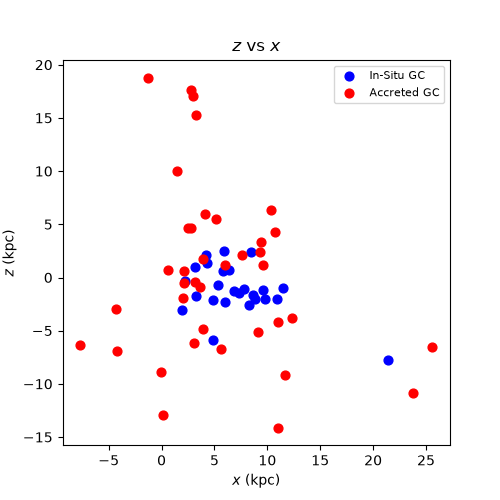

In [88]:
import numpy as np
import matplotlib.pyplot as plt
import mplcursors

# Assuming x, z, mask, and filtered_will are already defined from your script
cluster_ids = np.asarray(filtered_will['cluster_id'], dtype=str)

fig, axes = plt.subplots(1, figsize=(5, 5))

# Plot the In-Situ GC points
scatter_other = axes.scatter(
    x[~mask], z[~mask], 
    color='blue', s=40, label='In-Situ GC'
)

# Plot the Accreted GC points
scatter_mask = axes.scatter(
    x[mask], z[mask], 
    color='red', s=40, label='Accreted GC'
)

axes.set_xlabel('$x$ (kpc)')
axes.set_ylabel('$z$ (kpc)')
axes.set_title ('$z$ vs $x$')

axes.legend(fontsize=8)

# Add Hover with Cluster IDs & Coordinates
cursor = mplcursors.cursor([scatter_other, scatter_mask], hover=True)

@cursor.connect("add")
def on_add(sel):
    idx = sel.index
    
    # Match the clicked point back to the correct cluster name string using the mask
    if sel.artist == scatter_mask:
        name = cluster_ids[mask][idx]
    else:
        name = cluster_ids[~mask][idx]
        
    # Display the cluster name, X, and Z on hover
    sel.annotation.set_text(f"Cluster: {name}\nX: {sel.target[0]:.2f} kpc\nZ: {sel.target[1]:.2f} kpc")
    sel.annotation.get_bbox_patch().set(fc="white", alpha=0.9)

plt.show()